Machine Learning Foundation 
Regression Intro: Transforming Target (California Housing)

Dataset: `california_housing.csv`  
Target (y): `MedHouseVal` – median nilai rumah (dalam satuan ratusan ribu USD pada dataset California Housing).

Pastikan file CSV berada di folder `data/`.

Struktur folder

```text
data-mining/
├── data/
│   └── california_housing.csv
└── 02a_california_housing_transforming_target.ipynb
```

1. Import Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import normaltest, boxcox
from scipy.special import inv_boxcox

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures

%matplotlib inline

2. Load California Housing Data

In [2]:
file_path = "data/california_housing.csv"
housing_data = pd.read_csv(file_path)

housing_data.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [3]:
print("Ukuran dataset:", housing_data.shape)
print("\\nKolom dataset:")
print(housing_data.columns.tolist())
print("\\nInformasi dataset:")
housing_data.info()

Ukuran dataset: (20640, 9)
\nKolom dataset:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']
\nInformasi dataset:
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [4]:
housing_data.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


Menentukan target

Kolom `MedHouseVal` merupakan target yang akan diprediksi. Kolom lainnya digunakan sebagai predictor (X).

In [5]:
y_col = "MedHouseVal"

# Pastikan target tersedia dan tidak ada nilai kosong
print("Target tersedia:", y_col in housing_data.columns)
print("Jumlah missing values:", housing_data.isnull().sum().sum())
print("Nilai minimum target:", housing_data[y_col].min())

Target tersedia: True
Jumlah missing values: 0
Nilai minimum target: 0.14999


3. Determining Normality

Memeriksa distribusi target dengan dua cara: visualisasi histogram dan uji statistik.

3.1 Visual approach | Histogram

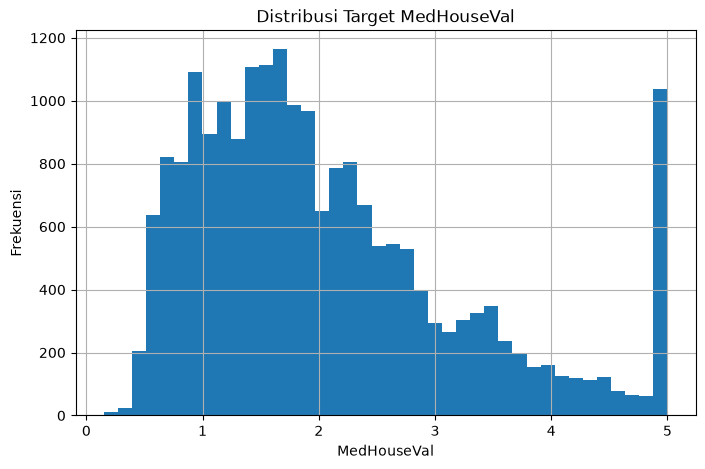

In [6]:
housing_data[y_col].hist(bins=40, figsize=(8, 5))
plt.title("Distribusi Target MedHouseVal")
plt.xlabel("MedHouseVal")
plt.ylabel("Frekuensi")
plt.show()

Perhatikan bentuk histogram. Distribusi yang memiliki ekor panjang ke kanan disebut right-skewed (miring ke kanan).

3.2 Statistical test – D'Agostino-Pearson normality test

Uji ini menghasilkan p-value. Dengan tingkat signifikansi 0,05:
- p-value < 0,05: tolak H₀ bahwa data berasal dari distribusi normal.
- p-value ≥ 0,05: gagal menolak H₀.

Pada dataset besar, uji normalitas sangat sensitif terhadap penyimpangan kecil.

In [7]:
stat_original = normaltest(housing_data[y_col].values)
print("Statistic:", stat_original.statistic)
print("P-value:", stat_original.pvalue)

Statistic: 2430.9310510660694
P-value: 0.0


4. Apply Transformations to Target

Log, Square Root, dan Box-Cox.

4.1 Log Transformation

Log transformation sering digunakan untuk mengurangi kemencengan ke kanan. Semua nilai target pada dataset ini positif, sehingga log dapat diterapkan.

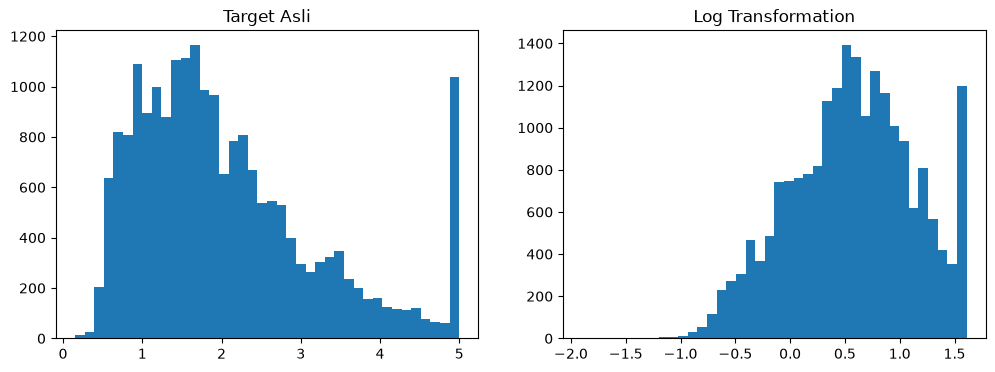

In [8]:
log_target = np.log(housing_data[y_col])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(housing_data[y_col], bins=40)
ax[0].set_title("Target Asli")
ax[1].hist(log_target, bins=40)
ax[1].set_title("Log Transformation")
plt.show()

In [9]:
log_test = normaltest(log_target)
print("Statistic:", log_test.statistic)
print("P-value:", log_test.pvalue)

Statistic: 359.5441835709388
P-value: 8.432814311328483e-79


4.2 Square Root Transformation

Square root transformation menggunakan akar kuadrat setiap nilai target. Karena target bernilai non negatif, transformasi ini dapat digunakan.

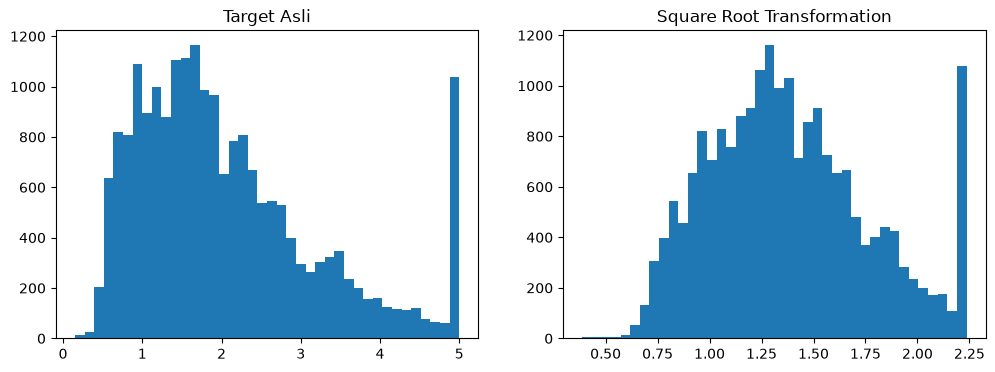

In [10]:
sqrt_target = np.sqrt(housing_data[y_col])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(housing_data[y_col], bins=40)
ax[0].set_title("Target Asli")
ax[1].hist(sqrt_target, bins=40)
ax[1].set_title("Square Root Transformation")
plt.show()

4.3 Box-Cox Transformation

Box-Cox merupakan transformasi berpangkat dengan parameter λ (lambda) yang dipilih untuk membuat distribusi lebih mendekati normal. Box-Cox mensyaratkan seluruh nilai target positif.

In [12]:
boxcox_result = boxcox(housing_data[y_col])
boxcox_target = boxcox_result[0]
lam = boxcox_result[1]

print("Lambda:", lam)

Lambda: 0.12474767032522126


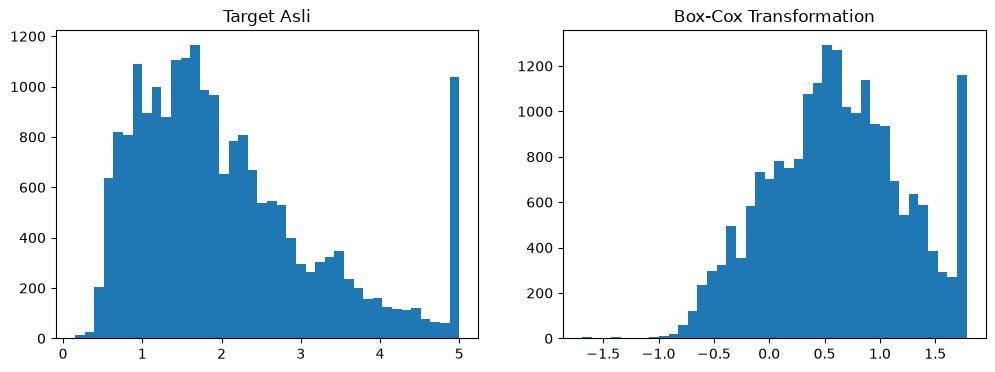

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(housing_data[y_col], bins=40)
ax[0].set_title("Target Asli")
ax[1].hist(boxcox_target, bins=40)
ax[1].set_title("Box-Cox Transformation")
plt.show()

In [14]:
boxcox_test = normaltest(boxcox_target)
print("Statistic:", boxcox_test.statistic)
print("P-value:", boxcox_test.pvalue)

Statistic: 446.7475267111986
P-value: 9.77253360897744e-98


Perbandingan hasil transformasi

In [15]:
normality_comparison = pd.DataFrame({
    "Transformasi": ["Asli", "Log", "Square Root", "Box-Cox"],
    "P-value": [
        stat_original.pvalue,
        log_test.pvalue,
        sqrt_test.pvalue,
        boxcox_test.pvalue
    ]
})
normality_comparison

,Transformasi,P-value
0,Asli,0.000000e+00
1,Log,8.432814e-79
2,Square Root,1.058636e-185
3,Box-Cox,9.772534e-98


5. Testing Regression

Menguji Linear Regression dengan target yang ditransformasi. Data dibagi menjadi 70% training dan 30% testing.

5.1 Define predictor (X) and target (y)

In [16]:
X = housing_data.drop(columns=[y_col])
y = housing_data[y_col]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (20640, 8)
y shape: (20640,)


5.2 Create Polynomial Features

In [17]:
pf = PolynomialFeatures(degree=2, include_bias=False)
X_pf = pf.fit_transform(X)

print("Jumlah fitur sebelum:", X.shape[1])
print("Jumlah fitur setelah polynomial:", X_pf.shape[1])

Jumlah fitur sebelum: 8
Jumlah fitur setelah polynomial: 44


5.3 Split data into Training and Test Sets

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X_pf, y, test_size=0.3, random_state=72018
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (14448, 44)
X_test: (6192, 44)


5.4 Normalize predictor data using StandardScaler

Scaler di-fit hanya pada data training, lalu digunakan untuk mentransformasi data testing.

In [19]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

5.5 Transform training target using Box-Cox

Gunakan parameter lambda dari data training. Parameter ini kemudian dipakai untuk inverse transformation pada prediksi.

In [20]:
y_train_bc, lam_train = boxcox(y_train)

print("Lambda dari y_train:", lam_train)
print("Shape target training:", y_train_bc.shape)

Lambda dari y_train: 0.12782527804559218
Shape target training: (14448,)


5.6 Fit Regression, Predict, and Inverse Transform

1. Latih model dengan X training yang sudah di-scale dan y training yang sudah di-Box-Cox.
2. Prediksi target testing dalam skala Box-Cox.
3. Kembalikan prediksi ke skala target asli menggunakan `inv_boxcox()`.

In [21]:
lr_bc = LinearRegression()
lr_bc.fit(X_train_s, y_train_bc)

y_pred_bc = lr_bc.predict(X_test_s)
y_pred_inverse = inv_boxcox(y_pred_bc, lam_train)

print("Contoh prediksi setelah inverse transformation:")
print(y_pred_inverse[:10])

Contoh prediksi setelah inverse transformation:
[1.2102359  1.29332862 2.8644693  2.61994118 2.21112626 1.39468184
 1.80915164 1.08821626 1.07940321 2.60190328]


5.7 Evaluate R² after inverse transformation

In [22]:
r2_boxcox = r2_score(y_test, y_pred_inverse)
print("R² Linear Regression dengan Box-Cox target:", r2_boxcox)

R² Linear Regression dengan Box-Cox target: -13.16255523395745


Sumber Dataset

Mendeley Data - California Housing Dataset

Simpan file sebagai `data/california_housing.csv` sebelum menjalankan notebook.